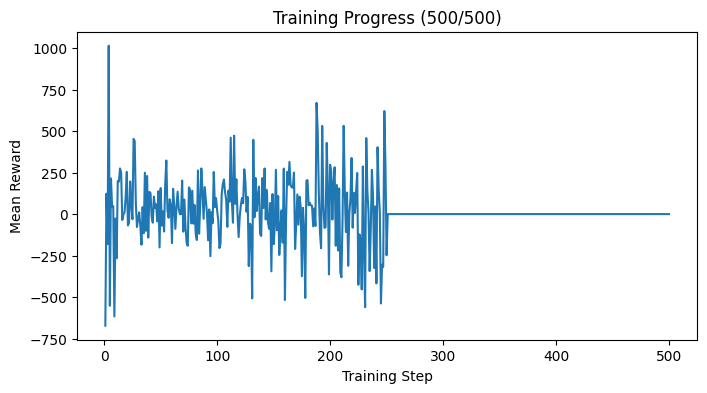

In [ ]:
from stable_baselines3 import SAC
from trader import LivePlotCallback
from trader import StockDataLoader
from trader import TraderEnvironment

total_timesteps = 500
budget = 10000
period = "1y"
tickers = ["ASML", "NVDA", "SPY"]

data, data_rl, num_features, num_stocks, prices = StockDataLoader(
    tickers, period=period
).load()
env = TraderEnvironment(
    num_features=num_features,
    num_stocks=num_stocks,
    data=data_rl,
    prices=prices,
    budget=budget,
)
callback = LivePlotCallback(total_timesteps=total_timesteps)

model = SAC(
    "MlpPolicy",
    env,
    verbose=0,
    device="cuda",
)

trained_model = model.learn(
    total_timesteps=total_timesteps, log_interval=4, callback=callback
)